# 14 · Visualizar siniestros de tráfico en Barcelona

**Pregunta del módulo.** ¿En qué zonas y franjas horarias conviene revisar primero los expedientes registrados?

Vamos a cargar el CSV del curso, comprobar qué estamos contando y construir gráficos con pandas y Seaborn. Usaremos Matplotlib para el anillo, las barras apiladas y el área apilada. Al final hay una demostración opcional de cómo preparar un resumen con Spark para dibujarlo en Python.

**Ruta para clase.** Empieza por barras, histograma, línea, dispersión, barras al 100 %, mapa de calor y mapa. Los demás gráficos forman una galería que puedes intercalar según el tiempo. Las celdas muestran ejemplos completos.

## 0 · Abrir el notebook y preparar el entorno

- **Jupyter o VS Code.** Abre el cuaderno desde el repositorio y selecciona un kernel de Python. El CSV está en `PySpark/data`.
- **Colab.** Abre el notebook y sube el CSV con el botón del panel **Archivos**. Mantén el nombre `2023_accidents_causa_conductor_gu_bcn_.csv`.
- Si falta alguna biblioteca, ejecuta en una celda `%pip install pandas "seaborn>=0.13" matplotlib folium`. Los gráficos de Seaborn funcionan sin conexión una vez instaladas las bibliotecas y descargado el CSV. El mapa geográfico usa Folium y necesita conexión para cargar las calles de OpenStreetMap.

## 1 · Cargar los datos y decidir qué cuenta como un siniestro

El archivo contiene registros de causas vinculados a expedientes. Un expediente puede ocupar varias filas. Para los gráficos de siniestros dejamos **una fila por expediente** después de comprobar que las filas repetidas coinciden en fecha, hora y ubicación. Guardamos el archivo original en `registros` por si queremos analizar las causas por separado.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:

sns.set_theme(style="whitegrid")

ruta = '../data/2023_accidents_causa_conductor_gu_bcn_.csv'

registros = pd.read_csv(ruta)
registros.head()

,Numero_expedient,Codi_districte,Nom_districte,Codi_barri,Nom_barri,Codi_carrer,Nom_carrer,Num_postal,Descripcio_dia_setmana,NK_Any,Mes_any,Nom_mes,Dia_mes,Hora_dia,Descripcio_torn,Descripcio_causa_mediata,Coordenada_UTM_X_ED50,Coordenada_UTM_Y_ED50,Longitud_WGS84,Latitud_WGS84
0,2023S000699,-1,Desconegut,-1,Desconegut,-1,Rovira (ascendent) ...,0,Dissabte,2023,2,Febrer,4,16,Tarda,Manca d'atenció a la conducció,430443.36,4585232.00,2.166596,41.413783
1,2023S005197,-1,Desconegut,-1,Desconegut,-1,Estatut de Catalunya ...,11,Divendres,2023,9,Setembre,1,13,Matí,No respectar distàncies,429493.73,4587108.15,2.155015,41.430598
2,2023S007430,-1,Desconegut,-1,Desconegut,-1,Rovira (ascendent) ...,0,Divendres,2023,12,Desembre,15,11,Matí,No respectar distàncies,430443.36,4585232.00,2.166596,41.413783
3,2023S000961,-1,Desconegut,-1,Desconegut,-1,Amílcar ...,120,Dissabte,2023,1,Gener,28,14,Tarda,No respectat pas de vianants,430955.45,4586335.10,2.172596,41.423762
4,2023S006486,-1,Desconegut,-1,Desconegut,-1,Augusta / Hort de la Vila ...,NaN,Dijous,2023,11,Novembre,2,14,Tarda,Desobeir semàfor,426883.33,4583690.92,2.124189,41.399587


In [4]:
campos = {
    'Numero_expedient': 'expedient',
    'Nom_districte': 'districte',
    'Nom_barri': 'barri',
    'Descripcio_torn': 'torn',
    'NK_Any': 'year',
    'Mes_any': 'month',
    'Dia_mes': 'day',
    'Hora_dia': 'hora',
    'Latitud_WGS84': 'latitud',
    'Longitud_WGS84': 'longitud',
}
tabla = registros[list(campos)].rename(columns=campos).copy()
tabla['expedient'] = tabla['expedient'].str.strip().replace('', pd.NA)
print(f"Filas de origen: {len(tabla):,}")
print(f"Filas sin expediente: {tabla['expedient'].isna().sum():,}")
tabla = tabla.dropna(subset=['expedient'])

# Antes de quedarnos con una fila, comprobamos que las demás dicen lo mismo.
conflictos = tabla.groupby('expedient').nunique(dropna=False).gt(1).any(axis=1)
print(f"Expedientes con conflictos: {conflictos.sum():,}")

siniestros = tabla.drop_duplicates(subset='expedient').copy()
siniestros['data'] = pd.to_datetime(siniestros[['year', 'month', 'day']])

dias = ['Dilluns', 'Dimarts', 'Dimecres', 'Dijous', 'Divendres', 'Dissabte', 'Diumenge']
turnos = ['Matí', 'Tarda', 'Nit']
siniestros['dia_setmana'] = siniestros['data'].dt.dayofweek.map(dict(enumerate(dias)))
siniestros['mes'] = siniestros['data'].dt.to_period('M').dt.to_timestamp()

print(f"Expedientes distintos: {len(siniestros):,}")
print(f"Expedientes con distrito desconocido: {siniestros['districte'].eq('Desconegut').sum():,}")
siniestros[['districte', 'barri', 'data', 'hora', 'torn']].head()

Filas de origen: 8,897
Filas sin expediente: 0
Expedientes con conflictos: 0
Expedientes distintos: 7,721
Expedientes con distrito desconocido: 90


,districte,barri,data,hora,torn
0,Desconegut,Desconegut,2023-02-04,16,Tarda
1,Desconegut,Desconegut,2023-09-01,13,Matí
2,Desconegut,Desconegut,2023-12-15,11,Matí
3,Desconegut,Desconegut,2023-01-28,14,Tarda
4,Desconegut,Desconegut,2023-11-02,14,Tarda


In [5]:
siniestros.to_csv('../data/2023_accidents_causa_conductor_gu_bcn_siniestros.csv', index=False, encoding='utf-8-sig')

**Para comentar.** El CSV tiene 8.897 filas y 7.721 expedientes. El número de filas puede servir para describir el archivo. Para describir el número de siniestros usamos expedientes distintos. La categoría «Desconegut» se mantiene visible para poder valorar la cobertura territorial.

In [6]:
# Tablas pequeñas para alimentar los gráficos.
por_distrito = (siniestros.groupby('districte').size().rename('expedients')
                .sort_values(ascending=False).reset_index())
por_turno = siniestros.groupby('torn').size().reindex(turnos, fill_value=0)
por_turno = por_turno.rename('expedients').reset_index()
por_turno['percentatge'] = 100 * por_turno['expedients'] / len(siniestros)

# Los días sin expedientes se representan como cero dentro del año cubierto.
calendario = pd.date_range('2023-01-01', '2023-12-31', freq='D', name='data')
por_dia = (siniestros.groupby('data').size().reindex(calendario, fill_value=0)
           .rename('expedients').reset_index())
por_dia['dia_setmana'] = por_dia['data'].dt.dayofweek.map(dict(enumerate(dias)))
por_mes = (por_dia.groupby(pd.Grouper(key='data', freq='MS'))['expedients']
           .sum().reset_index())

colores_turno = {'Matí': '#067276', 'Tarda': '#613A89', 'Nit': '#B65C15'}

## 2 · Una variable categórica o numérica

Las **barras** comparan categorías. El **histograma** muestra cómo se distribuye una medida numérica. El **diagrama de caja** resume esa distribución. En los dos últimos gráficos la unidad pasa a ser el **día**, con su total de expedientes.

### 01 · Barras horizontales | una variable categórica

¿Qué distritos tienen más expedientes registrados? Con Seaborn usamos `data` para elegir la tabla y `x` e `y` para indicar sus columnas. Una barra horizontal facilita leer nombres largos. Las barras muestran volumen registrado. Para comparar el riesgo necesitaríamos un denominador, por ejemplo el volumen de tráfico.

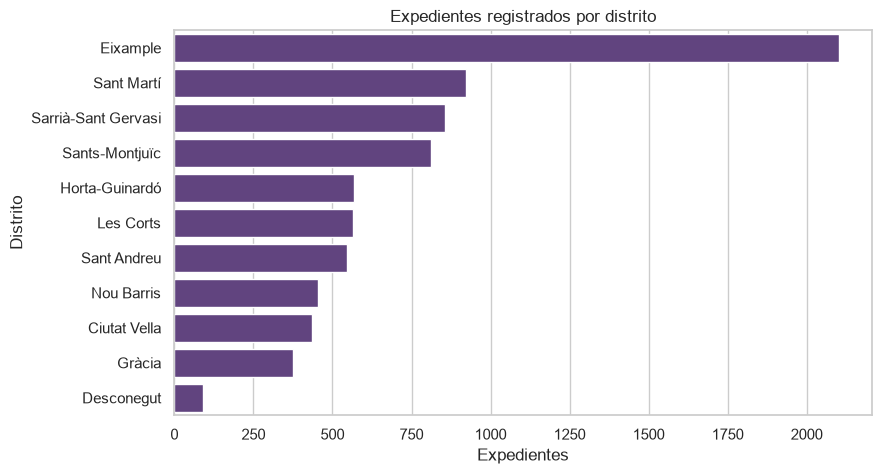

In [7]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=por_distrito, x='expedients', y='districte', color='#613A89')
ax.set(title='Expedientes registrados por distrito', xlabel='Expedientes', ylabel='Distrito')
plt.show()

### 02 · Histograma | una variable numérica

¿Cuántos expedientes suele haber en un día? El eje horizontal agrupa totales diarios en intervalos. La altura indica cuántos días hay en cada intervalo.

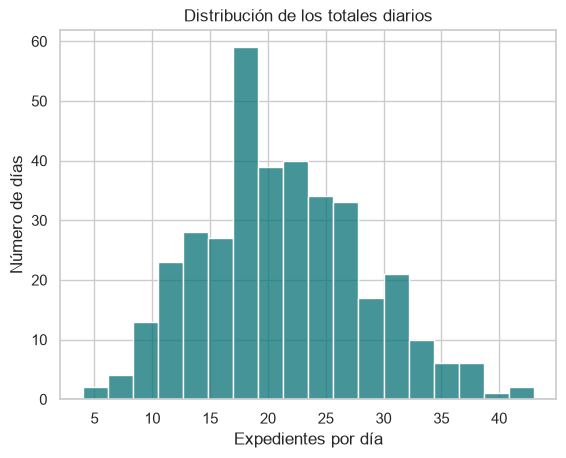

In [8]:
ax = sns.histplot(data=por_dia, x='expedients', bins=18, color='#067276')
ax.set(title='Distribución de los totales diarios', xlabel='Expedientes por día', ylabel='Número de días')
plt.show()

### 03 · Diagrama de caja | resumen de una distribución

La línea dentro de la caja es la mediana. La caja contiene la mitad central de los días. Los puntos que quedan fuera merecen revisión y pueden ser válidos.

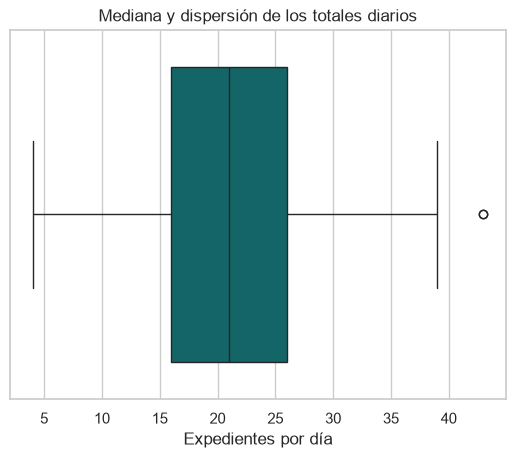

In [9]:
ax = sns.boxplot(data=por_dia, x='expedients', color='#067276')
ax.set(title='Mediana y dispersión de los totales diarios', xlabel='Expedientes por día')
plt.show()

## 3 · Proporciones y denominadores

Una proporción divide una parte por un total. Escribe siempre de qué total hablas. Aquí cada expediente tiene un solo turno. Si contáramos categorías de causas, un mismo expediente podría estar en varias y los porcentajes podrían sumar más del 100 %.

### 04 · Barras de porcentaje | comparación precisa

¿Qué porcentaje del total corresponde a cada turno? Las barras permiten comparar diferencias con facilidad. Los turnos pueden tener duraciones distintas.

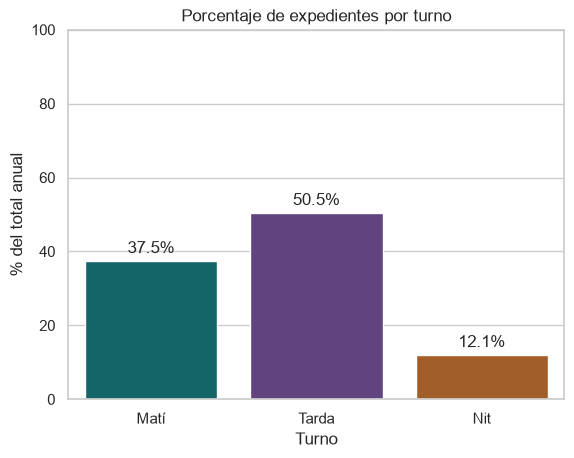

In [10]:
ax = sns.barplot(data=por_turno, x='torn', y='percentatge', hue='torn',
                 order=turnos, palette=colores_turno, legend=False)
ax.set(title='Porcentaje de expedientes por turno', xlabel='Turno', ylabel='% del total anual')
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.1f%%', padding=3)
ax.set_ylim(0, 100)
plt.show()

### 05 · Anillo | partes de un total con pocas categorías

Muestra los mismos datos como partes de un total. Es útil para explicar la composición general con pocas categorías. Compara con las barras si quieres distinguir porcentajes cercanos.

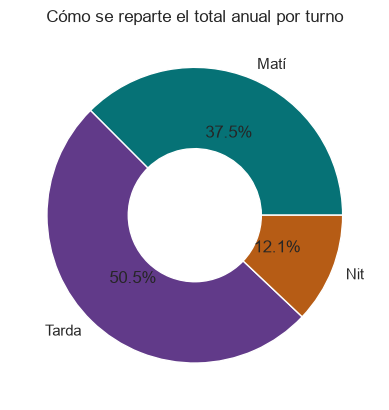

In [11]:
fig, ax = plt.subplots()
ax.pie(por_turno['expedients'], labels=por_turno['torn'],
       colors=[colores_turno[turno] for turno in por_turno['torn']],
       autopct='%.1f%%', wedgeprops={'width': 0.55})
ax.set_title('Cómo se reparte el total anual por turno')
plt.show()

## 4 · Dos variables

Con una fecha y una medida podemos ver evolución. Con una categoría y una medida podemos comparar distribuciones. Con dos medidas numéricas podemos explorar si cambian juntas.

### 06 · Línea temporal | fecha y medida numérica

¿Cómo cambia el recuento de un mes a otro? Ordenamos el eje por fecha. Los meses tienen distinta duración. Si eso importa para la comparación, podemos calcular expedientes por día.

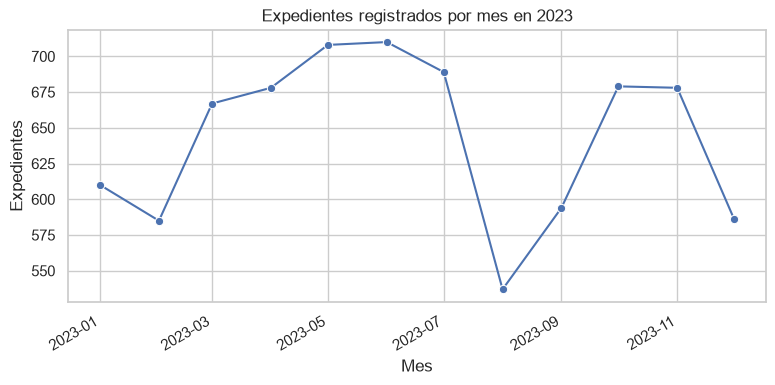

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(data=por_mes, x='data', y='expedients', marker='o', ax=ax)
ax.set(title='Expedientes registrados por mes en 2023', xlabel='Mes', ylabel='Expedientes')
fig.autofmt_xdate()
plt.show()

### 07 · Cajas por categoría | día de la semana y total diario

¿Son parecidos los totales diarios de lunes y sábados? Una caja por día de la semana permite comparar la mediana y la dispersión entre categorías.

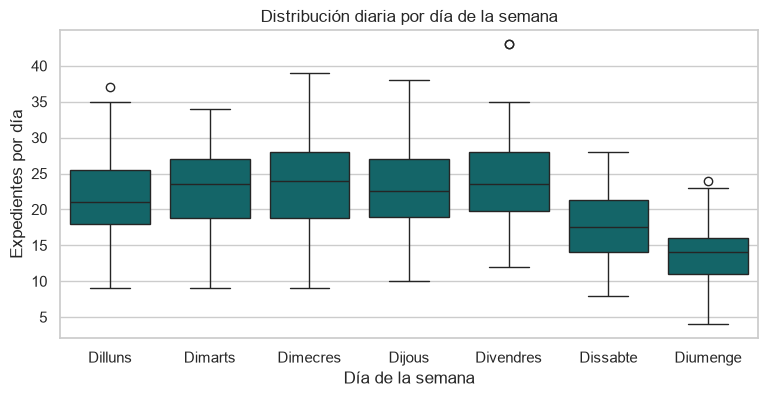

In [13]:
plt.figure(figsize=(9, 4))
ax = sns.boxplot(data=por_dia, x='dia_setmana', y='expedients', order=dias, color='#067276')
ax.set(title='Distribución diaria por día de la semana', xlabel='Día de la semana', ylabel='Expedientes por día')
plt.show()

### 08 · Violín | forma de la distribución por categoría

Usa los mismos datos que el gráfico anterior. El ancho de cada violín muestra dónde se concentran los valores. El contorno es una estimación suavizada. En grupos pequeños conviene ver también los valores individuales.

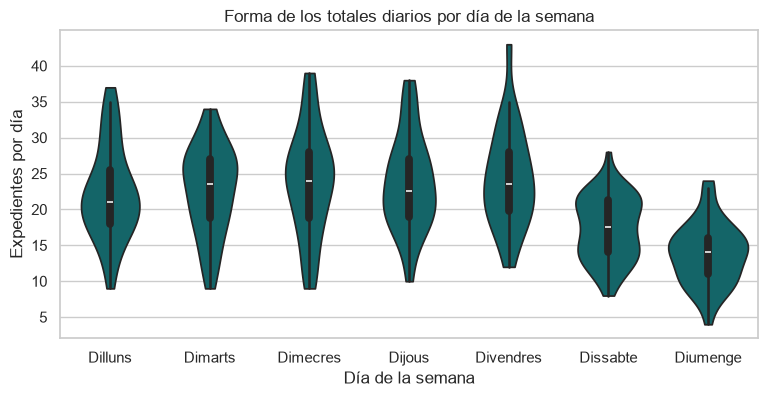

In [14]:
plt.figure(figsize=(9, 4))
ax = sns.violinplot(data=por_dia, x='dia_setmana', y='expedients',
                    order=dias, inner='box', cut=0, color='#067276')
ax.set(title='Forma de los totales diarios por día de la semana', xlabel='Día de la semana', ylabel='Expedientes por día')
plt.show()

### 09 · Dispersión | dos variables numéricas

¿Los días con más expedientes por la matí también suelen tener más por la tarda? Cada punto es un día. La posición muestra sus dos recuentos. Días con la misma combinación pueden quedar superpuestos.

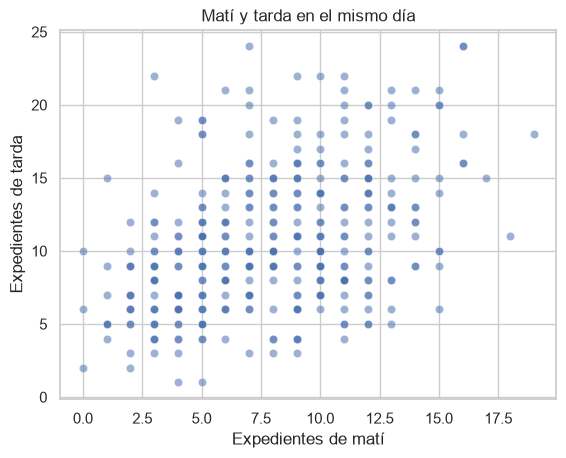

In [15]:
por_dia_turno = (pd.crosstab(siniestros['data'], siniestros['torn'])
                 .reindex(index=calendario, columns=turnos, fill_value=0).reset_index())
por_dia_turno['tipus_dia'] = por_dia_turno['data'].dt.dayofweek.map(
    lambda dia: 'Cap de setmana' if dia >= 5 else 'Entre setmana'
)


ax = sns.scatterplot(data=por_dia_turno, x='Matí', y='Tarda', alpha=0.55)
ax.set(title='Matí y tarda en el mismo día', xlabel='Expedientes de matí', ylabel='Expedientes de tarda')
plt.show()

## 5 · Tres variables y composición por grupo

Podemos añadir una variable usando color, paneles o tamaño. Primero leemos los ejes. Después comprobamos qué significa el color o el tamaño. Cada elemento visual tiene que responder a una parte de la pregunta.

### 10 · Dispersión con color | dos medidas y una categoría

Añadimos el tipo de día al gráfico anterior. El color separa los días entre semana de los fines de semana. Buscamos diferencias entre los patrones antes de interpretar la nube completa.

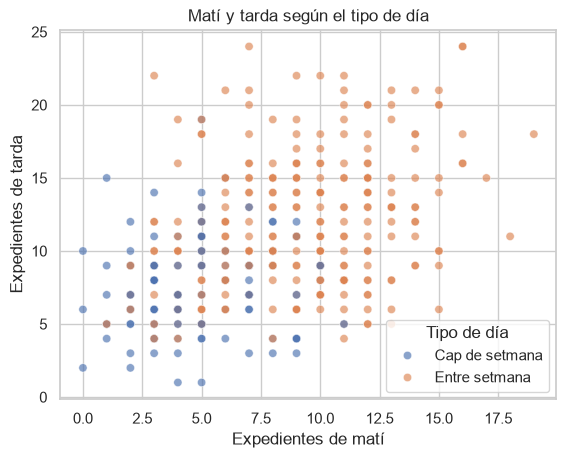

In [16]:
ax = sns.scatterplot(data=por_dia_turno, x='Matí', y='Tarda', hue='tipus_dia', alpha=0.65)
ax.set(title='Matí y tarda según el tipo de día', xlabel='Expedientes de matí', ylabel='Expedientes de tarda')
ax.legend(title='Tipo de día')
plt.show()

### 11 · Barras agrupadas | dos categorías y un recuento

¿Cuántos expedientes hubo en cada turno dentro de cada distrito? Las barras se colocan lado a lado para comparar cantidades.

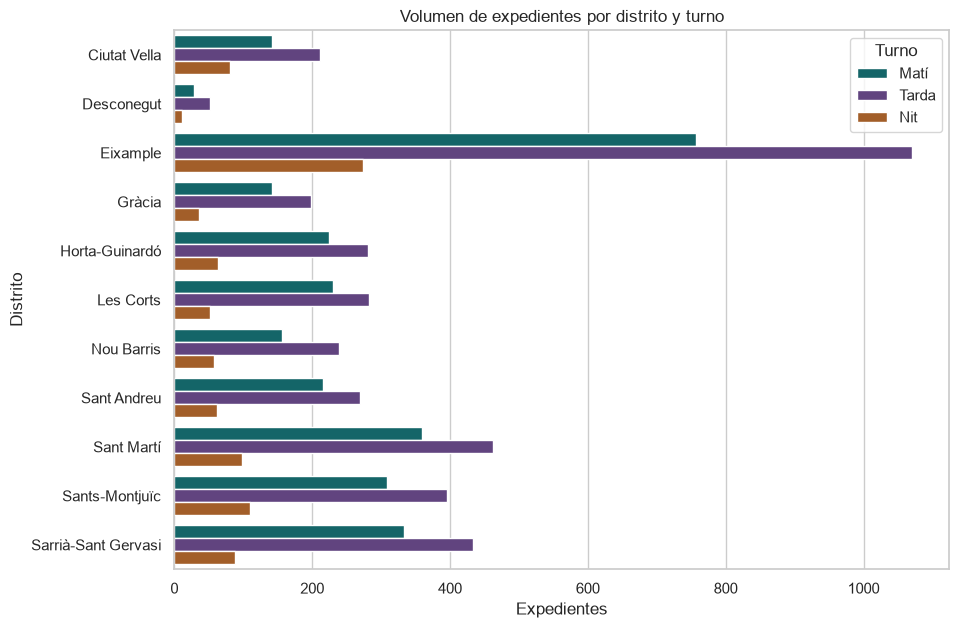

In [17]:
distrito_turno = (siniestros.groupby(['districte', 'torn']).size()
                  .rename('expedients').reset_index())

plt.figure(figsize=(10, 7))
ax = sns.barplot(data=distrito_turno, x='expedients', y='districte', hue='torn',
                 hue_order=turnos, palette=colores_turno, errorbar=None)
ax.set(title='Volumen de expedientes por distrito y turno', xlabel='Expedientes', ylabel='Distrito')
ax.legend(title='Turno')
plt.show()

### 12 · Barras apiladas al 100 % | comparar proporciones

Cada barra usa como denominador el total de su propio distrito. Dos distritos pueden tener proporciones parecidas y cantidades muy distintas. Consulta los recuentos en `distrito_turno` para dar contexto a los porcentajes.

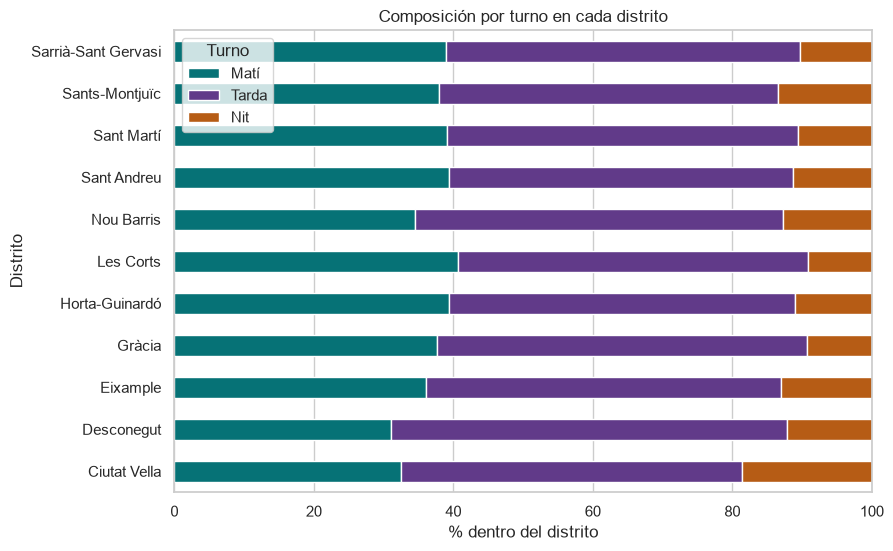

In [18]:
distrito_turno['percentatge'] = (100 * distrito_turno['expedients']
                               / distrito_turno.groupby('districte')['expedients'].transform('sum'))
proporciones = (distrito_turno.pivot(index='districte', columns='torn', values='percentatge')
                .reindex(columns=turnos).fillna(0))
ax = proporciones.plot.barh(stacked=True, color=[colores_turno[t] for t in turnos], figsize=(9, 6))
ax.set(title='Composición por turno en cada distrito', xlabel='% dentro del distrito', ylabel='Distrito', xlim=(0, 100))
ax.legend(title='Turno')
plt.show()

### 13 · Mapa de calor | día, hora y recuento

Cada celda cruza un día de la semana con una hora. El color representa cuántos expedientes se registraron en esa combinación. Es una forma rápida de localizar franjas para revisar.

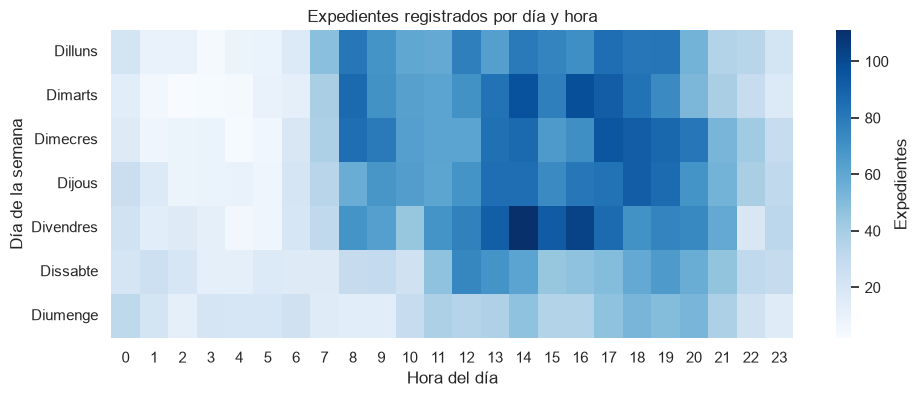

In [19]:
dia_hora = pd.crosstab(siniestros['dia_setmana'], siniestros['hora'])
dia_hora = dia_hora.reindex(index=dias, columns=range(24), fill_value=0)

plt.figure(figsize=(11, 4))
ax = sns.heatmap(dia_hora, cmap='Blues', cbar_kws={'label': 'Expedientes'})
ax.set(title='Expedientes registrados por día y hora', xlabel='Hora del día', ylabel='Día de la semana')
plt.show()

### 14 · Área apilada | evolución y composición

La altura total muestra el volumen del mes. El grosor de cada banda muestra la aportación de un turno. La línea simple del ejemplo 06 suele ser más fácil de leer si solo interesa el total.

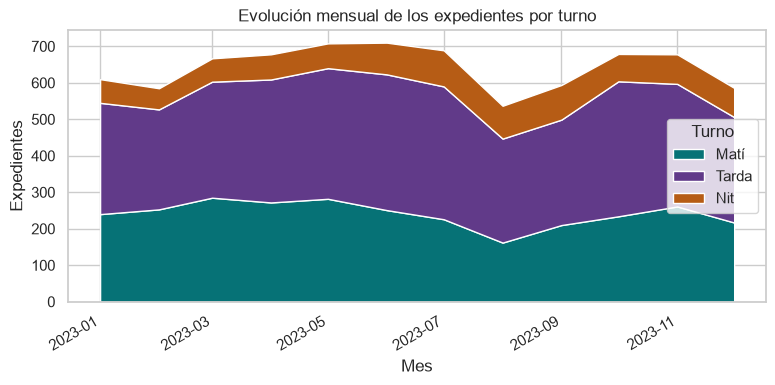

In [20]:
mes_turno = (siniestros.groupby(['mes', 'torn']).size()
             .rename('expedients').reset_index().sort_values('mes'))

series_turno = (mes_turno.pivot(index='mes', columns='torn', values='expedients')
                .reindex(columns=turnos).fillna(0))
fig, ax = plt.subplots(figsize=(9, 4))
ax.stackplot(series_turno.index, *[series_turno[t] for t in turnos],
             labels=turnos, colors=[colores_turno[t] for t in turnos])
ax.set(title='Evolución mensual de los expedientes por turno', xlabel='Mes', ylabel='Expedientes')
ax.legend(title='Turno')
fig.autofmt_xdate()
plt.show()

### 15 · Paneles pequeños | un gráfico por turno

Separamos la serie temporal en tres paneles, uno por turno. Como comparten la escala vertical, es más fácil comparar tanto las cantidades como los cambios. Compáralos con el área apilada.

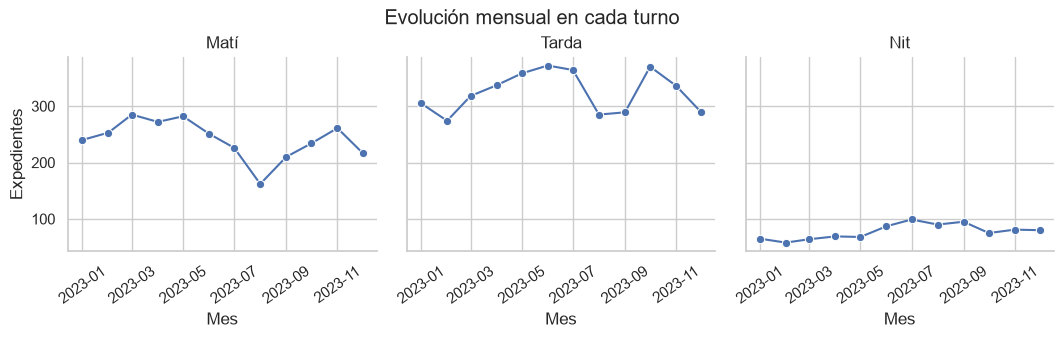

In [21]:
paneles = sns.relplot(data=mes_turno, kind='line', x='mes', y='expedients',
                     col='torn', col_order=turnos, marker='o', height=3, aspect=1.2)
paneles.set_axis_labels('Mes', 'Expedientes')
paneles.set_titles('{col_name}')
for ax in paneles.axes.flat:
    ax.tick_params(axis='x', labelrotation=35)
paneles.figure.suptitle('Evolución mensual en cada turno', y=1.03)
plt.show()

## 6 · Ubicación

Un mapa responde **dónde**. Aquí el punto representa una celda aproximada de coordenadas, y su tamaño indica cuántos expedientes quedaron dentro. El recuento observado puede reflejar que por una zona pasan más vehículos. Para comparar riesgo haría falta información de exposición.

### 16 · Mapa geográfico | latitud, longitud y recuento

Folium coloca los puntos sobre un mapa de Barcelona. Agrupamos las coordenadas en celdas de 0,005 grados para reducir las marcas. El tamaño del círculo representa el número de expedientes de esa celda. Al pasar el ratón verás su recuento. Puedes acercarte para ubicar las zonas respecto a las calles.

In [22]:
import folium

ubicados = siniestros.dropna(subset=['latitud', 'longitud']).copy()
paso = 0.005
for columna in ['latitud', 'longitud']:
    ubicados[columna] = (ubicados[columna].div(paso).round().mul(paso)).round(3)

celdas_mapa = (ubicados.groupby(['latitud', 'longitud']).size()
               .rename('expedients').reset_index())
print(f'Expedientes con coordenadas: {len(ubicados):,} de {len(siniestros):,}')
print(f'Burbujas del mapa: {len(celdas_mapa):,}')



mapa = folium.Map(
    location=[41.39, 2.16],
    zoom_start=12,
    tiles='https://geoserveis.icgc.cat/servei/catalunya/mapa-base/wmts/topografic/MON3857NW/{z}/{x}/{y}.png',
    attr='© <a href="https://www.icgc.cat/">ICGC</a> · <a href="https://www.openstreetmap.org/copyright">OpenStreetMap contributors</a>',
)
for fila in celdas_mapa.itertuples(index=False):
    folium.CircleMarker(
        location=[fila.latitud, fila.longitud],
        radius=2 + fila.expedients**0.5,
        color='#067276', fill=True, fill_opacity=0.65,
        tooltip=f'{fila.expedients} expedientes en esta celda',
    ).add_to(mapa)

mapa

Expedientes con coordenadas: 7,721 de 7,721
Burbujas del mapa: 376


**Cómo leer el mapa.** Los círculos señalan el centro aproximado de cada celda. Son recuentos de expedientes registrados. Para comparar riesgo entre calles o zonas necesitaríamos también saber cuánto tráfico circula por ellas. [Mapas interactivos con Folium](https://python-visualization.github.io/folium/latest/user_guide/map.html)

### 17 · Mapa coroplético | recuento por distrito

Cada distrito se colorea según su total de expedientes registrados en 2023. Cuanto más oscuro es el azul, mayor es el recuento. Pasa el cursor por un distrito para ver su nombre y su total. Usamos el resumen por distrito que ya calculamos y los polígonos del GeoJSON. Los expedientes con distrito «Desconegut» quedan fuera de este mapa. [Límites administrativos de Open Data BCN, adaptados a WGS84](https://datos.gob.es/es/catalogo/l01080193-unidades-administrativas-de-la-ciudad-de-barcelona)

In [23]:
import json
from pathlib import Path

ruta_districtes = Path('../data/districtes_barcelona.geojson')
districtes = json.loads(ruta_districtes.read_text(encoding='utf-8'))
comptes = por_distrito.set_index('districte')['expedients'].to_dict()

for zona in districtes['features']:
    nom = zona['properties']['districte']
    zona['properties']['expedients'] = comptes[nom]

mapa_districtes = folium.Map(location=[41.40, 2.15], tiles=None)
capa = folium.Choropleth(
    geo_data=districtes,
    data=por_distrito[por_distrito['districte'] != 'Desconegut'],
    columns=['districte', 'expedients'],
    key_on='feature.properties.districte',
    bins=[0, 400, 800, 1200, 1600, 2000, 2400],
    fill_color='Blues',
    fill_opacity=0.85,
    line_color='#34495e',
    line_opacity=0.8,
    legend_name='Expedients registrats per districte (2023)',
    highlight=True,
).add_to(mapa_districtes)

folium.GeoJsonTooltip(
    fields=['districte', 'expedients'],
    aliases=['Districte', 'Expedients'],
).add_to(capa.geojson)

mapa_districtes.fit_bounds(capa.geojson.get_bounds())
mapa_districtes

**Cómo comparar los dos mapas.** En el mapa de burbujas redondeamos las coordenadas y cada círculo representa una celda de una cuadrícula. Mira dentro de un distrito para localizar concentraciones aproximadas. En el mapa de color el distrito entero toma un único tono según su total. Sirve para comparar distritos. Por ejemplo, Eixample es el más oscuro, con **2.101 expedientes**. El color resume el total y la distribución dentro de cada distrito se aprecia en el mapa de burbujas.

El mapa de burbujas incluye **7.721 expedientes con coordenadas**. El de distritos representa **7.631**, porque hay **90** con distrito «Desconegut». Los dos muestran recuentos registrados. Para comparar el riesgo entre distritos necesitaríamos una medida de exposición al tráfico, como el número de desplazamientos.

## 7 · Ejercicio final. Elige el gráfico y defiende tu respuesta

Trabaja con `siniestros`, que contiene una fila por expediente. Responde con un gráfico y una frase que cite una cifra. Indica el periodo, las unidades y el denominador cuando uses porcentajes. Hay varias formas válidas de resolver cada pregunta.

1. **Comparar categorías.** ¿Cuáles son los cinco barrios con más expedientes registrados durante el primer semestre? Mantén aparte los registros con barrio desconocido e indica cuántos son.
2. **Describir una medida.** ¿Cómo se distribuye el número diario de expedientes los fines de semana? Señala un valor típico y explica qué harías si vieras un día muy alejado del resto.
3. **Ver un cambio en el tiempo.** ¿En qué meses se registraron más expedientes de nit? Compara el total mensual con el promedio diario del mes y comprueba si cambia la lectura.
4. **Comparar proporciones.** ¿Qué turno representa la mayor proporción de expedientes en Eixample y en Sant Martí? Indica el total que sirve de base a los porcentajes en cada distrito.
5. **Relacionar dos medidas.** ¿Cómo se relacionan los recuentos de tarda y nit en un mismo día? Añade una tercera variable para ver si la lectura cambia entre días de lunes a viernes y fines de semana.
6. **Cruzar categorías.** ¿Qué combinación de día de la semana y hora destacarías para revisar en Eixample durante el segundo semestre? Indica cuántos expedientes hay en la celda que señalas.
7. **Ubicar un patrón.** Representa en un mapa geográfico los expedientes del turno de nit. ¿Qué celdas revisarías primero? Explica qué dato adicional necesitarías para comparar el riesgo entre zonas.

Lo ideal es que respondas al menos una, pero bien puedes responderlas todas!

Entonces, responde la pregunta inicial:
**¿En qué zonas y franjas horarias conviene revisar primero los expedientes registrados?**

[Volver al README](../README.md) · [CSV del curso](../data/2023_accidents_causa_conductor_gu_bcn_.csv) · [Construir el panel](15_panel_siniestros.ipynb) · [Guía de Seaborn](https://seaborn.pydata.org/tutorial/function_overview.html)

In [24]:
# Añade una celda por pregunta.
# 1. Filtra las filas que responden a tu pregunta.
# 2. Prepara la tabla y dibuja el gráfico.
# 3. Escribe tu interpretación en una celda de texto.